# Step 7.a -- BIO-variables from ERA5 (1981-2015) at 1deg, MIRCA2000 no-threshold presence,
with a calendar shift (sensitivity test, option A from the adaptable-calendar discussion)

**Pure input-perturbation clone of
[1.1.d)_preprocessing_BIOvariables_ERA5_MIRCA2000_no_threshold.ipynb](../../../1_preprocessing_BIOvariables/1.1\)_preprocessing_biovariables_ERA5/1.1.d\)_preprocessing_BIOvariables_ERA5_MIRCA2000_no_threshold.ipynb)**
(no-threshold MIRCA2000 presence branch, chosen for this test per the user's 2026-10-19
decision). The only change: `sowing_doy_full` and `maturity_doy_full` are shifted by a fixed
`CALENDAR_SHIFT_DAYS` (and `anthesis_doy_full` recomputed as `maturity_doy_full - 60` *after*
the shift, so the whole season moves together) right after the nearest-neighbour calendar
fill, before BIO variables are computed. Nothing else changes: same ERA5 climate, same grid,
same ETo formula, same `compute_bio_variables` logic.

This answers "how much does the SVM's climate-only suitability change if the growing season
were uniformly `CALENDAR_SHIFT_DAYS` earlier/later than MIRCA2000's historical calendar?" --
Section 6 of `Crop_Suitability_SVM_Report.docx` flags the fixed-calendar assumption as a
limitation; this is the sensitivity test envisaged there (folder was previously an empty
stub, `7_test_adaptable_calendar/README.md`).

Writes to its own `outputs_ERA5_MIRCA2000_no_threshold_shift_<N>/` folder under this
subfolder -- nothing in `0_preprocessing_masks/` or `1_preprocessing_BIOvariables/` is read differently or written to; this notebook
only *reads* from there (same `ERA5_1DEG`, same crop-mask file as `1.1.d)`).

**Scope (per the user's decision)**: Maize_rf only, shifts in {-20, -10, 0, +10, +20} days.
The already-trained no-threshold model
(`3.d)_SVM_train_ERA5_MIRCA2000_no_threshold/svm_train_outputs_mirca2000_no_threshold/svm_model_Maize_rf.joblib`)
is reused unchanged in `7.c)` -- **no retraining**: the model only ever sees BIO01-12 values,
and is calendar-agnostic by construction (see the discussion that preceded this notebook).


In [1]:
import os; os.environ.setdefault("HDF5_USE_FILE_LOCKING", "FALSE")   # BDAP/EOS refuses HDF5 file locks ("NetCDF: HDF error")
import numpy as np
import xarray as xr
import pandas as pd
import datetime
import matplotlib.pyplot as plt
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

# Inputs from 0.1)_preprocessing_input_data (all on the 1° SVM grid, integer centres):
#   ERA5 1° daily  : outputs_input_data_1deg/ERA5_1deg_<var>_1981_2015_daily.nc
#   MIRCA2000 1°   : outputs_input_data_1deg/mirca2000_1deg_<Crop>_<rf|ir>.nc (presence, sowing/maturity DOY)
# No separate land-mask file is read: 0.1's ERA5 regridding keeps a node only if it is land in a
# land 1° cell, so a 1° cell has data iff it is land -- the grid and the land mask both come from
# that NaN pattern, exactly as the pipeline did before with the BA-masked ERA5 file.
BASE = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "0_Input_data").is_dir())  # racine du projet (local ou BDAP)
import sys; sys.path.insert(0, str(BASE)); import crop_utils as cu   # helpers + config reader (project root)
CFG = cu.load_config()   # config/config_<profile>.json, written by 00_config_and_inventory.ipynb
ERA5_1DEG  = BASE / "1_SVM" / "0_preprocessing_masks" / "outputs_input_data_1deg"
BASE_7A    = BASE / "1_SVM" / "7_test_adaptable_calendar" / "7.a)_Build_BIOvariables_shifted_calendar_ERA5"
# OUT_ERA5 is set in the config-dependent cell below (depends on CALENDAR_SHIFT_DAYS)
OUT_MASKS  = ERA5_1DEG   # MIRCA2000 crop masks live in outputs_input_data_1deg (0.1)

LAT_MIN, LAT_MAX = 35.0, 71.0
LON_MIN, LON_MAX = -25.0, 44.0

print(f'ERA5 1° dir : {ERA5_1DEG}  (exists: {ERA5_1DEG.exists()})')
print(f'crop mask dir: {OUT_MASKS}  (exists: {OUT_MASKS.exists()})')  # = ERA5_1DEG, 0.1 output

import time as _time

def save_with_retry(save_fn, path, retries=8, delay=3):
    """Retry a file-write a few times on PermissionError/FileNotFoundError, which this
    machine's OneDrive sync has been observed to raise transiently right after a brand-new
    output subfolder is created (confirmed by direct repro during development -- not an
    xarray/netCDF4/matplotlib bug, a cloud-sync race). save_fn() must perform the write."""
    last_exc = None
    for attempt in range(retries):
        try:
            save_fn()
            return
        except (PermissionError, FileNotFoundError) as e:
            last_exc = e
            print(f"  [retry {attempt+1}/{retries}] {type(e).__name__} writing {path.name} -- waiting {delay}s...")
            _time.sleep(delay)
    raise last_exc


ERA5 1° dir : C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\0_preprocessing_masks\outputs_input_data_1deg  (exists: True)
crop mask dir: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\0_preprocessing_masks\outputs_input_data_1deg  (exists: True)


In [2]:
# ╔══════════════════════════════════════════════════════════════════════════╗
# ║  PARAMÈTRES — modifier ici, puis relancer les cellules marquées [RUN]  ║
# ╚══════════════════════════════════════════════════════════════════════════╝

# Culture : 'Wheat-spring' | 'Wheat-winter' | 'Maize' | 'Rice' | 'Soybean'
CROP_NAME  = 'Maize'

# Type d'irrigation : 'rf' (rainfed) | 'ir' (irrigated)
IRRIG_TYPE = 'rf'

# Calendar shift (days) applied to sowing_doy_full AND maturity_doy_full together,
# after the nearest-neighbour fill, before BIO variables are computed.
# -20 | -10 | 0 | +10 | +20  -- set by the runner script per execution.
CALENDAR_SHIFT_DAYS = -60

# ── Ne pas modifier ci-dessous ─────────────────────────────────────────────
season_label = f'{CROP_NAME}_{IRRIG_TYPE}'

print(f"Crop          : {CROP_NAME} ({IRRIG_TYPE})")
print(f"Output label  : {season_label}")
print()
print("Cellules a relancer pour ce parametrage :")
print("  [RUN] cell-apply-masks  -> regrid masks")
print("  [RUN] fill_calendar_nn  -> fill calendar to all land")
print("  [RUN] cell-run-bio      -> compute BIO variables")
print("  [RUN] cell-save         -> save NetCDF")
print("  [RUN] cell-training     -> build CSV")
print("  [RUN] cell-plots        -> diagnostic maps")

# Output dir depends on the shift -- each shift value gets its own folder, nothing overwritten
# NB: kept deliberately SHORT (just 'out_<tag>', not a long descriptive name) -- the
# original long folder+file naming pushed the full path to exactly 260 chars, Windows's
# MAX_PATH limit, causing intermittent Permission/FileNotFoundError on write that looked
# like a OneDrive lock but wasn't (confirmed by direct repro: a long-but-fresh filename
# failed identically, a short one in the same folder always succeeded).
shift_tag = 'cal' + ('0' if CALENDAR_SHIFT_DAYS == 0 else
                     ('P' if CALENDAR_SHIFT_DAYS > 0 else 'M') + str(abs(CALENDAR_SHIFT_DAYS)))
OUT_ERA5 = BASE_7A / f'out_{shift_tag}'
OUT_ERA5.mkdir(parents=True, exist_ok=True)
print(f'CALENDAR_SHIFT_DAYS = {CALENDAR_SHIFT_DAYS}')
print(f'OUT_ERA5 = {OUT_ERA5}')

Crop          : Maize (rf)
Output label  : Maize_rf

Cellules a relancer pour ce parametrage :
  [RUN] cell-apply-masks  -> regrid masks
  [RUN] fill_calendar_nn  -> fill calendar to all land
  [RUN] cell-run-bio      -> compute BIO variables
  [RUN] cell-save         -> save NetCDF
  [RUN] cell-training     -> build CSV
  [RUN] cell-plots        -> diagnostic maps
CALENDAR_SHIFT_DAYS = -60
OUT_ERA5 = C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.a)_Build_BIOvariables_shifted_calendar_ERA5\out_calM60


## 1. Target grid + land mask (read from the BA pipeline's own masked ERA5 file)

**1° grid, integer centres**, and the **land mask itself** — both read directly from
`5)ECearth`'s already-masked ERA5 file, so both are guaranteed byte-identical to what the
BA pipeline actually used (not recomputed independently via `regionmask`).

In [3]:
# ── Target grid + land mask: from the NaN pattern of ERA5 1° (0.1 output) ─────
# 0.1 regrids ERA5 keeping only land nodes inside land 1° cells, so a cell has data (not NaN)
# iff it is land. No separate land-mask file needed.
sample_file = ERA5_1DEG / "ERA5_1deg_tasmax_1981_2015_daily.nc"
if not sample_file.exists():
    raise FileNotFoundError(
        f"ERA5 1 degre introuvable : {sample_file} -- execute d'abord 0.1)_preprocessing_input_data.ipynb.")
ds_grid = xr.open_dataset(sample_file)
da_ref  = ds_grid['tasmax']
target_lats_asc = da_ref.lat.values   # 35.0, 36.0, ..., 71.0  (37 points)
target_lons     = da_ref.lon.values   # -25.0, ..., 44.0 (70 points)
land_mask = np.isfinite(da_ref.isel(time=0).values)
ds_grid.close()

nlat = len(target_lats_asc)
nlon = len(target_lons)

print(f"Target grid (1 degre, integer centres, from 0.1 ERA5):")
print(f"  lat: {target_lats_asc[0]:.1f} -> {target_lats_asc[-1]:.1f}  n={nlat}")
print(f"  lon: {target_lons[0]:.1f} -> {target_lons[-1]:.1f}  n={nlon}")
print(f"  Total pixels: {nlat * nlon}")
print(f"Land pixels : {land_mask.sum()} / {land_mask.size}")

Target grid (1 degre, integer centres, from 0.1 ERA5):
  lat: 35.0 -> 71.0  n=37
  lon: -25.0 -> 44.0  n=70
  Total pixels: 2590
Land pixels : 1332 / 2590


## 2. Load ERA5 1° (already regridded + masked by the BA pipeline)

Units (from `ERA5_daily_preparation.ipynb`, unchanged through the BA regridding):
- `tasmax` / `tasmin` : °C  
- `pr` : mm/day  
- `dswrf` : W/m² → × 0.0864 → MJ/m²/day

Already masked (ocean = NaN) — no need to reapply `land_mask` to these arrays later.

In [4]:
def load_era5_1deg(var):
    """ERA5 1° daily from 0.1 (0.25° land nodes in land 1° cells, mean per 1° cell).
    Returns DataArray (time, lat, lon) on the target grid, ocean-only cells = NaN."""
    ds  = xr.open_dataset(ERA5_1DEG / f"ERA5_1deg_{var}_1981_2015_daily.nc")
    da  = ds[var].sel(lat=target_lats_asc, lon=target_lons).transpose('time', 'lat', 'lon')
    return da.load()

print("Loading ERA5 1° (1.0 outputs)...")
tmax_C = load_era5_1deg("tasmax")
tmin_C = load_era5_1deg("tasmin")
pr_mm  = load_era5_1deg("pr")
sw_raw = load_era5_1deg("dswrf")
sw_MJ  = sw_raw * 0.0864   # W/m² → MJ/m²/day

times = tmax_C.time.values
print(f"Grid  : {nlat} lat x {nlon} lon, {len(times)} days")
print(f"Period: {str(times[0])[:10]} → {str(times[-1])[:10]}")

s = dict(time='1990-07-15', method='nearest')
print(f"\nSanity check (Jul 1990, lat~40N, lon~15E):")
print(f"  Tmax : {float(tmax_C.sel(**s).sel(lat=40.0, lon=15.0, method='nearest')):.1f} degC")
print(f"  Pr   : {float(pr_mm.sel(**s).sel(lat=40.0, lon=15.0, method='nearest')):.2f} mm/day")
print(f"  Solar: {float(sw_MJ.sel(**s).sel(lat=40.0, lon=15.0, method='nearest')):.1f} MJ/m2/day")

Loading ERA5 1° (1.0 outputs)...


Grid  : 37 lat x 70 lon, 12783 days
Period: 1981-01-01 → 2015-12-31

Sanity check (Jul 1990, lat~40N, lon~15E):
  Tmax : nan degC
  Pr   : nan mm/day
  Solar: nan MJ/m2/day


## Land mask — visualization

`land_mask` was already derived in Section 1 from the BA pipeline's masked ERA5 file —
this cell just plots it.

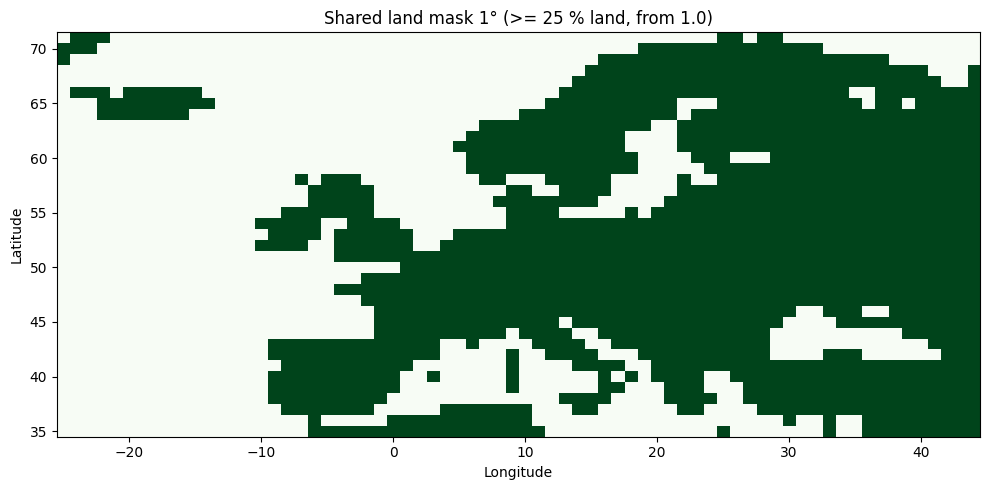

In [5]:
# Land mask plot (the file itself is produced by 0.1)
fig, ax = plt.subplots(figsize=(10, 5))
ax.imshow(land_mask, origin='lower', aspect='auto', cmap='Greens',
          extent=[target_lons[0]-0.5, target_lons[-1]+0.5,
                  target_lats_asc[0]-0.5, target_lats_asc[-1]+0.5])
ax.set_title('Shared land mask 1° (>= 25 % land, from 0.1)')
ax.set_xlabel('Longitude'); ax.set_ylabel('Latitude')
plt.tight_layout(); plt.show()

## 4. Regrid crop masks from 0.25° to ERA5/BA 1° grid

MIRCA2000 masks (0.25°, centres à x.875/x.625/x.375/x.125) → BA pipeline 1° (centres entiers)  
Chaque cellule 1° couvre exactement **4 × 4 = 16 sous-pixels** MIRCA2000.

In [6]:
# Crop masks are already 1° (from 0.1): only the calendar gap-filler is kept.

def fill_calendar_nn(cal_arr, land_mask, k=5):
    """
    Fill NaN land pixels with an inverse-distance-weighted mean of the k nearest valid
    pixels (distance in degrees, longitude scaled by cos(lat)). Replaces the previous
    1-nearest-neighbour fill, which produced sharp calendar blocks. Ocean stays NaN.
    """
    from scipy.spatial import cKDTree
    LA, LO = np.meshgrid(target_lats_asc, target_lons, indexing='ij')
    X = np.column_stack([LA.ravel(), (LO * np.cos(np.radians(55.0))).ravel()])
    known   = (~np.isnan(cal_arr) & land_mask).ravel()
    to_fill = (np.isnan(cal_arr) & land_mask).ravel()
    if not known.any() or not to_fill.any(): return cal_arr
    kk = min(k, int(known.sum()))
    d, ix = cKDTree(X[known]).query(X[to_fill], k=kk)
    d = np.maximum(d.reshape(-1, kk), 0.5); ix = ix.reshape(-1, kk)
    w = 1.0 / d**2
    vals = cal_arr.ravel()[known][ix]
    out = cal_arr.copy().ravel()
    out[to_fill] = (w * vals).sum(1) / w.sum(1)
    return out.reshape(cal_arr.shape)

print("Regrid functions defined (MIRCA2000 0.25deg -> BA pipeline 1deg integer centres, 4x4 sub-pixels).")

Regrid functions defined (MIRCA2000 0.25deg -> BA pipeline 1deg integer centres, 4x4 sub-pixels).


In [7]:
# [RUN] quand tu changes CROP_NAME ou IRRIG_TYPE
crop_mask_nc = OUT_MASKS / f"mirca2000_no_threshold_1deg_{season_label}.nc"  # MIRCA2000, no 5% threshold
print(f"  {'OK' if crop_mask_nc.exists() else 'MISSING'} : {crop_mask_nc.name}")
cm = xr.open_dataset(crop_mask_nc)
pres_1deg = cm['presence'].values.astype(float)           # 1 = MIRCA crop present (5 % rule), 0 otherwise
sowing_doy = cm['sowing_doy'].values.astype(float)        # NaN where no crop
maturity_doy = cm['maturity_doy'].values.astype(float)    # may exceed 365 (harvest next year)
cm.close()

# wheat_mask keeps the name used below: 1 = presence on land, 0 = no crop
wheat_mask = np.where(land_mask, pres_1deg, np.nan)
print(f"  Presence cells in window: {int(np.nansum(wheat_mask == 1))}")

anthesis_doy = maturity_doy - 60   # Ceglar et al. 2021

def doy2str(d):
    if np.isnan(d): return 'NaN'
    return (datetime.date(2000,1,1) + datetime.timedelta(days=int(d)-1)).strftime('%b %d')

print(f"\nCalendar check -- {season_label}:")
locs = {'France (47N,2E)':(47,2), 'Italy (42N,13E)':(42,13),
        'Germany (51N,10E)':(51,10), 'Ukraine (49N,32E)':(49,32)}
print(f"  {'Location':22s}  Sowing      Anthesis    Maturity")
for name, (lat, lon) in locs.items():
    i_ = np.argmin(np.abs(target_lats_asc - lat))
    j_ = np.argmin(np.abs(target_lons - lon))
    print(f"  {name:22s}  {doy2str(sowing_doy[i_,j_]):10s}  "
          f"{doy2str(anthesis_doy[i_,j_]):10s}  {doy2str(maturity_doy[i_,j_]):10s}")

  OK : mirca2000_no_threshold_1deg_Maize_rf.nc


  Presence cells in window: 979

Calendar check -- Maize_rf:
  Location                Sowing      Anthesis    Maturity


  France (47N,2E)         Apr 15      Jul 16      Sep 14    


  Italy (42N,13E)         Apr 15      Jul 16      Sep 14    
  Germany (51N,10E)       NaN         NaN         NaN       
  Ukraine (49N,32E)       May 15      Aug 15      Oct 14    


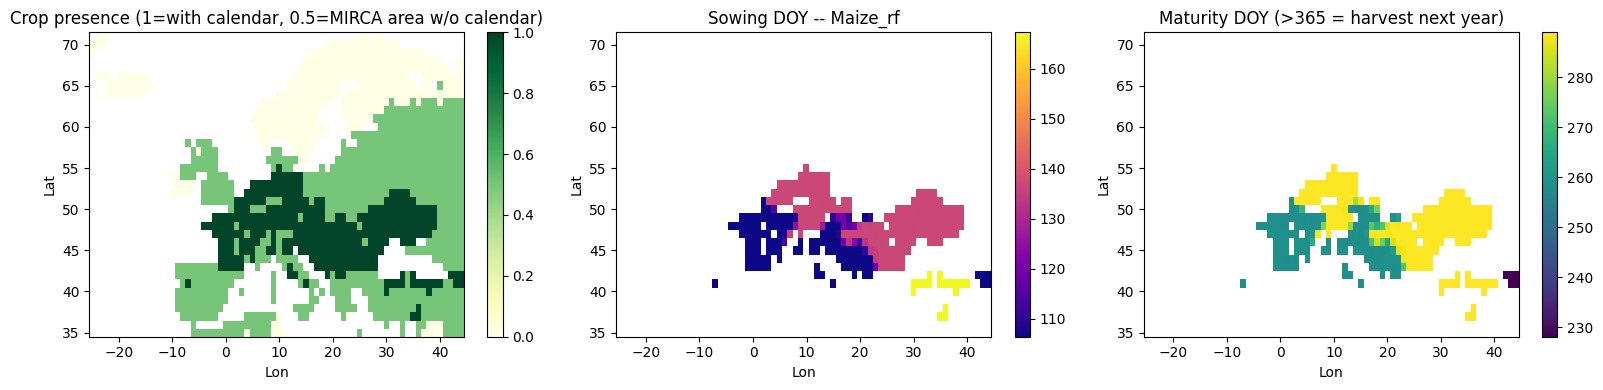

In [8]:
ext = [target_lons[0]-0.5, target_lons[-1]+0.5,
       target_lats_asc[0]-0.5, target_lats_asc[-1]+0.5]

# presence with a calendar = 1 (used as SVM label); MIRCA area without any calendar = 0.5
presence_plot = np.where((wheat_mask == 1) & np.isnan(sowing_doy), 0.5, wheat_mask)
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, d, t, cmap in zip(axes,
    [presence_plot, sowing_doy, maturity_doy],
    ['Crop presence (1=with calendar, 0.5=MIRCA area w/o calendar)', f'Sowing DOY -- {season_label}', 'Maturity DOY (>365 = harvest next year)'],
    ['YlGn', 'plasma', 'viridis']):
    im = ax.imshow(d, origin='lower', aspect='auto', cmap=cmap, extent=ext)
    ax.set_title(t); ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
    plt.colorbar(im, ax=ax)
plt.tight_layout()
_mask_png_out = OUT_ERA5 / f'masks_{season_label}_{shift_tag}.png'
save_with_retry(lambda: plt.savefig(_mask_png_out, dpi=100), _mask_png_out)
plt.show()

In [9]:
from scipy.interpolate import NearestNDInterpolator

# fill_calendar_nn (IDW, k=5) is defined in the calendar-functions cell above

# Fill sowing and maturity DOY for ALL land pixels (non-wheat land gets nearest-neighbor)
sowing_doy_full   = fill_calendar_nn(sowing_doy,   land_mask)
maturity_doy_full = fill_calendar_nn(maturity_doy, land_mask)

# --- calendar shift (sensitivity test) -- shift the whole season together, before
# anthesis is recomputed, so anthesis stays maturity-60 relative to the SHIFTED maturity ---
sowing_doy_full   = sowing_doy_full   + CALENDAR_SHIFT_DAYS
maturity_doy_full = maturity_doy_full + CALENDAR_SHIFT_DAYS
anthesis_doy_full = maturity_doy_full - 60
print(f'Calendar shift applied: {CALENDAR_SHIFT_DAYS:+d} days '
      f'(sowing/maturity/anthesis all shifted together)')

n_wheat  = int(np.nansum(wheat_mask == 1))
n_filled = int(np.sum(~np.isnan(sowing_doy_full) & land_mask))
print(f"Calendar filling:")
print(f"  Wheat pixels with calendar     : {int(np.sum(~np.isnan(sowing_doy) & land_mask))}")
print(f"  Land pixels after NN fill      : {n_filled}")
print(f"  Non-wheat land pixels (class 0): {n_filled - n_wheat}")

Calendar shift applied: -60 days (sowing/maturity/anthesis all shifted together)
Calendar filling:
  Wheat pixels with calendar     : 315
  Land pixels after NN fill      : 1332
  Non-wheat land pixels (class 0): 353


## 5. ETo — Hargreaves method
$$ET_0 = 0.0023 \times R_a \times (T_{mean} + 17.8) \times \sqrt{T_{max} - T_{min}}$$

In [10]:
def compute_Ra(lat_rad_2d, doy):
    Gsc   = 0.0820
    dr    = 1 + 0.033 * np.cos(2 * np.pi / 365 * doy)
    delta = 0.409 * np.sin(2 * np.pi / 365 * doy - 1.39)
    ws    = np.arccos(np.clip(-np.tan(lat_rad_2d) * np.tan(delta), -1, 1))
    return (24*60/np.pi)*Gsc*dr*(ws*np.sin(lat_rad_2d)*np.sin(delta)
                                  + np.cos(lat_rad_2d)*np.cos(delta)*np.sin(ws))

def compute_ETo_day(tmax_day, tmin_day, lat_rad_2d, doy):
    # BUG FIX: Ra from compute_Ra() is in MJ/m2/day (extraterrestrial radiation); the
    # Hargreaves formula needs it as mm/day equivalent (Ra_mm = Ra / lambda). This division
    # was missing here, inflating ETo by a factor of ~lambda (~2.4-2.5x) -- confirmed against
    # AgERA5 Penman-Monteith reference in 1.a)_ET0_method.ipynb. 2_GAEZ's own Hargreaves
    # notebook already does this correctly; this fix makes 1.a consistent with it.
    Tmean = (tmax_day + tmin_day) / 2.0
    TD    = np.maximum(tmax_day - tmin_day, 0.0)
    lam   = 2.501 - 0.002361 * Tmean          # latent heat of vaporization (MJ/kg), temp-dependent
    Ra_mm = compute_Ra(lat_rad_2d, doy) / lam  # MJ/m2/day -> mm/day equivalent
    return 0.0023 * Ra_mm * (Tmean + 17.8) * np.sqrt(TD)

print("ETo functions defined.")

ETo functions defined.


## 6. Compute BIO variables (1981–2015 climatology)

In [11]:
print("Loading arrays into memory (lecture depuis OneDrive, peut prendre quelques minutes)...")
TMAX = tmax_C.values   # (T, nlat, nlon) degC — already masked (ocean = NaN)
print("  tasmax loaded")
TMIN = tmin_C.values
print("  tasmin loaded")
PR   = pr_mm.values    # mm/day
print("  pr loaded")
SW   = sw_MJ.values    # MJ/m2/day
print("  dswrf loaded")

dates      = pd.DatetimeIndex(tmax_C.time.values)
doys_all   = dates.dayofyear.values
lat_rad_2d = np.radians(target_lats_asc[:, None]) * np.ones((1, nlon))

print(f"\nData shape: {TMAX.shape}")
print("Precomputing ETo for all days...")
ETO = np.full_like(TMAX, np.nan)
for t in range(len(dates)):
    ETO[t] = compute_ETo_day(TMAX[t], TMIN[t], lat_rad_2d, doys_all[t])
    if t % 2000 == 0:
        print(f"  {t}/{len(dates)} days")
print("ETo done.")

Loading arrays into memory (lecture depuis OneDrive, peut prendre quelques minutes)...
  tasmax loaded
  tasmin loaded
  pr loaded
  dswrf loaded

Data shape: (12783, 37, 70)
Precomputing ETo for all days...
  0/12783 days


  2000/12783 days


  4000/12783 days


  6000/12783 days


  8000/12783 days


  10000/12783 days


  12000/12783 days
ETo done.


In [12]:
def compute_bio_variables(TMAX, TMIN, PR, SW, ETO, dates,
                          sowing_doy, anthesis_doy, maturity_doy):
    """
    12 BIO variables averaged over harvest years 1982-2015.
    Calendar days are counted on a 2-year axis (year hy-1 then hy). A season that ends
    in the calendar year of harvest (maturity_doy <= 365) uses year hy; a season that
    crosses New Year (maturity_doy > 365) starts in year hy-1 and ends in year hy.
    Seasons whose start year is missing from the data are skipped for that harvest year
    (each pixel is averaged over the years where it could be computed).
    """
    nlat, nlon = sowing_doy.shape
    yr_all  = dates.year.values
    doy_all = dates.dayofyear.values
    mon_all = dates.month.values
    harvest_years = list(range(1982, 2016))
    bio_sum = {i: np.zeros((nlat, nlon)) for i in range(1, 13)}
    bio_cnt = {i: np.zeros((nlat, nlon)) for i in range(1, 13)}
    valid   = ~np.isnan(sowing_doy) & ~np.isnan(maturity_doy)
    wrap    = valid & (maturity_doy > 365)
    yrs_present = set(yr_all)

    def ylen(y): return 366 if (y % 4 == 0 and (y % 100 != 0 or y % 400 == 0)) else 365

    for hy in harvest_years:
        print(f'  {hy}...', end=' ')
        if not (yr_all == hy).any(): print('skip'); continue
        idx = np.where((yr_all == hy) | (yr_all == hy - 1))[0]
        yr3  = yr_all[idx][:, None, None]
        doy3 = doy_all[idx][:, None, None]
        mon3 = mon_all[idx][:, None, None]
        t3   = doy3 + np.where(yr3 == hy, ylen(hy - 1), 0)          # day index on the 2-year axis
        shift = np.where(wrap, 0, ylen(hy - 1))[None]                # non-wrapping seasons live in year hy
        sow3 = np.nan_to_num(sowing_doy)[None] + shift
        ant3 = np.nan_to_num(anthesis_doy)[None] + shift
        mat3 = np.nan_to_num(maturity_doy)[None] + shift
        vp3  = valid[None] & (((hy - 1) in yrs_present) | ~wrap[None])

        p1 = (t3 >= sow3) & (t3 < ant3)
        p2 = (t3 >= ant3) & (t3 <= mat3)
        gs = (p1 | p2) & vp3; p1 = p1 & vp3; p2 = p2 & vp3

        tm = TMAX[idx]; tn = TMIN[idx]; pr = PR[idx]; sw = SW[idx]; et = ETO[idx]
        def pm(a, m): return np.nanmean(np.where(m, a, np.nan), axis=0)
        def acc(k, v):
            f = np.isfinite(v); bio_sum[k] += np.where(f, v, 0); bio_cnt[k] += f

        acc(1, pm(tm, p1)); acc(2, pm(tn, p1)); acc(3, pm(sw, p1))
        acc(4, pm(et, p1)); acc(5, pm(pr, p1))
        acc(6, pm(tm, p2)); acc(7, pm(tn, p2)); acc(8, pm(sw, p2))
        acc(9, pm(et, p2)); acc(10, pm(pr, p2))

        tmx = np.full((nlat, nlon), np.nan); tmn = np.full((nlat, nlon), np.nan)
        for m in range(1, 13):
            mm = gs & (mon3 == m)
            if not np.any(mm): continue
            tmx = np.fmax(tmx, np.nanmean(np.where(mm, tm, np.nan), axis=0))
            tmn = np.fmin(tmn, np.nanmean(np.where(mm, tn, np.nan), axis=0))
        acc(11, tmx); acc(12, tmn)
        print('ok')

    bio = {}
    for i in range(1, 13):
        with np.errstate(invalid='ignore', divide='ignore'):
            bio[i] = np.where(bio_cnt[i] > 0, bio_sum[i] / bio_cnt[i], np.nan)
        bio[i][~valid] = np.nan
    return bio

print('compute_bio_variables defined.')


compute_bio_variables defined.


In [13]:
print(f"Computing BIO variables -- {season_label}...")
bio = compute_bio_variables(
    TMAX, TMIN, PR, SW, ETO, dates,
    sowing_doy_full, anthesis_doy_full, maturity_doy_full   # calendrier rempli
)
print("\nDone:")
for i in range(1,13):
    n_valid = int(np.sum(~np.isnan(bio[i])))
    print(f"  BIO{i:02d}: {np.nanmin(bio[i]):.2f} -- {np.nanmax(bio[i]):.2f}  ({n_valid} valid pixels)")

Computing BIO variables -- Maize_rf...
  1982... 

ok
  1983... 

ok
  1984... 

ok
  1985... 

ok
  1986... 

...

ok
  2012... 

ok
  2013... 

ok
  2014... 

ok
  2015... 

ok

Done:
  BIO01: -8.69 -- 33.17  (1332 valid pixels)
  BIO02: -13.36 -- 19.66  (1332 valid pixels)
  BIO03: 11.08 -- 27.38  (1332 valid pixels)
  BIO04: 0.42 -- 6.13  (1332 valid pixels)
  BIO05: 0.20 -- 5.64  (1332 valid pixels)
  BIO06: 3.03 -- 41.81  (1332 valid pixels)
  BIO07: -0.78 -- 27.61  (1332 valid pixels)
  BIO08: 13.73 -- 28.89  (1332 valid pixels)
  BIO09: 1.12 -- 7.84  (1332 valid pixels)
  BIO10: 0.00 -- 6.84  (1332 valid pixels)
  BIO11: 4.11 -- 43.57  (1332 valid pixels)
  BIO12: -19.65 -- 15.36  (1332 valid pixels)


## 7. Save BIO variables (land pixels only)

In [14]:
bio_names = {
    1:'Avg Tmax sowing-anthesis [degC]',      2:'Avg Tmin sowing-anthesis [degC]',
    3:'Avg solar rad sowing-anthesis [MJ/m2/d]', 4:'Avg ETo sowing-anthesis [mm/d]',
    5:'Avg precip sowing-anthesis [mm/d]',    6:'Avg Tmax anthesis-maturity [degC]',
    7:'Avg Tmin anthesis-maturity [degC]',    8:'Avg solar rad anthesis-maturity [MJ/m2/d]',
    9:'Avg ETo anthesis-maturity [mm/d]',     10:'Avg precip anthesis-maturity [mm/d]',
    11:'Tmax warmest month sowing-maturity [degC]',
    12:'Tmin coldest month sowing-maturity [degC]',
}
data_vars = {}
for i in range(1, 13):
    arr = bio[i].copy(); arr[~land_mask] = np.nan
    data_vars[f'BIO{i:02d}'] = xr.DataArray(
        arr, dims=['lat', 'lon'],
        coords={'lat': target_lats_asc, 'lon': target_lons},
        attrs={'long_name': bio_names[i]}
    )
ds_bio = xr.Dataset(data_vars)
ds_bio.attrs['description'] = (
    f'BIO variables, ERA5 1981-2015, 1deg BA pipeline grid (integer centres), '
    f'Europe land, crop={season_label}, calendar_shift_days={CALENDAR_SHIFT_DAYS}'
)
out_nc = OUT_ERA5 / f'BIO_{season_label}_{shift_tag}.nc'  # kept short, see MAX_PATH note above
save_with_retry(lambda: ds_bio.to_netcdf(out_nc), out_nc)
print(f"Saved: {out_nc}")

Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.a)_Build_BIOvariables_shifted_calendar_ERA5\out_calM60\BIO_Maize_rf_calM60.nc


## 8. Build training dataset for SVM

In [15]:
rows = []
for i in range(nlat):
    for j in range(nlon):
        if not land_mask[i, j]: continue
        biovars = [bio[k][i, j] for k in range(1, 13)]
        if any(np.isnan(v) for v in biovars): continue
        # presence counts only where MIRCA also provides a calendar (else the season is invented)
        label = 1 if (not np.isnan(wheat_mask[i,j]) and wheat_mask[i,j]==1 and not np.isnan(sowing_doy_full[i,j])) else 0
        rows.append({
            'lat': target_lats_asc[i], 'lon': target_lons[j],
            **{f'BIO{k:02d}': bio[k][i,j] for k in range(1,13)},
            'label': label
        })

df = pd.DataFrame(rows)
print(f"Training dataset:")
print(f"  Total land pixels   : {len(df)}")
print(f"  Class 1 (presence)  : {(df.label==1).sum()}")
print(f"  Class 0 (background): {(df.label==0).sum()}")
print(f"  Imbalance ratio     : {(df.label==0).sum()/(df.label==1).sum():.1f}x")

out_csv = OUT_ERA5 / f'train_{season_label}_{shift_tag}.csv'
save_with_retry(lambda: df.to_csv(out_csv, index=False), out_csv)
print(f"Saved: {out_csv}")
df.head()

Training dataset:
  Total land pixels   : 1332
  Class 1 (presence)  : 979
  Class 0 (background): 353
  Imbalance ratio     : 0.4x
Saved: C:\Users\elisa\OneDrive - Politecnico di Milano\PHD_codes\crop_suitability_code_bdap\1_SVM\7_test_adaptable_calendar\7.a)_Build_BIOvariables_shifted_calendar_ERA5\out_calM60\train_Maize_rf_calM60.csv


,lat,lon,BIO01,BIO02,BIO03,BIO04,BIO05,BIO06,BIO07,BIO08,BIO09,BIO10,BIO11,BIO12,label
0,35,-6,20.398815,10.172587,19.540172,3.244243,2.774481,27.712031,16.017701,26.706622,5.237274,0.520334,30.393635,7.824545,1
1,35,-5,17.788891,8.366436,19.384777,2.916997,2.998683,26.022180,15.180636,26.700920,4.884772,0.784805,29.174242,5.901380,1
2,35,-4,17.261614,9.004272,20.680039,2.730846,1.952490,24.609564,15.805110,27.413645,4.352448,0.831219,27.394881,6.575462,1
3,35,-3,20.279058,10.449459,20.593148,3.185945,1.525646,27.492608,17.608120,26.871221,4.893876,0.502861,29.961019,7.825869,1
4,35,-2,20.091164,10.260499,20.457416,3.163188,1.485481,27.321692,17.642245,26.645706,4.830371,0.433911,29.826513,7.568917,1


## 9. Diagnostic plots

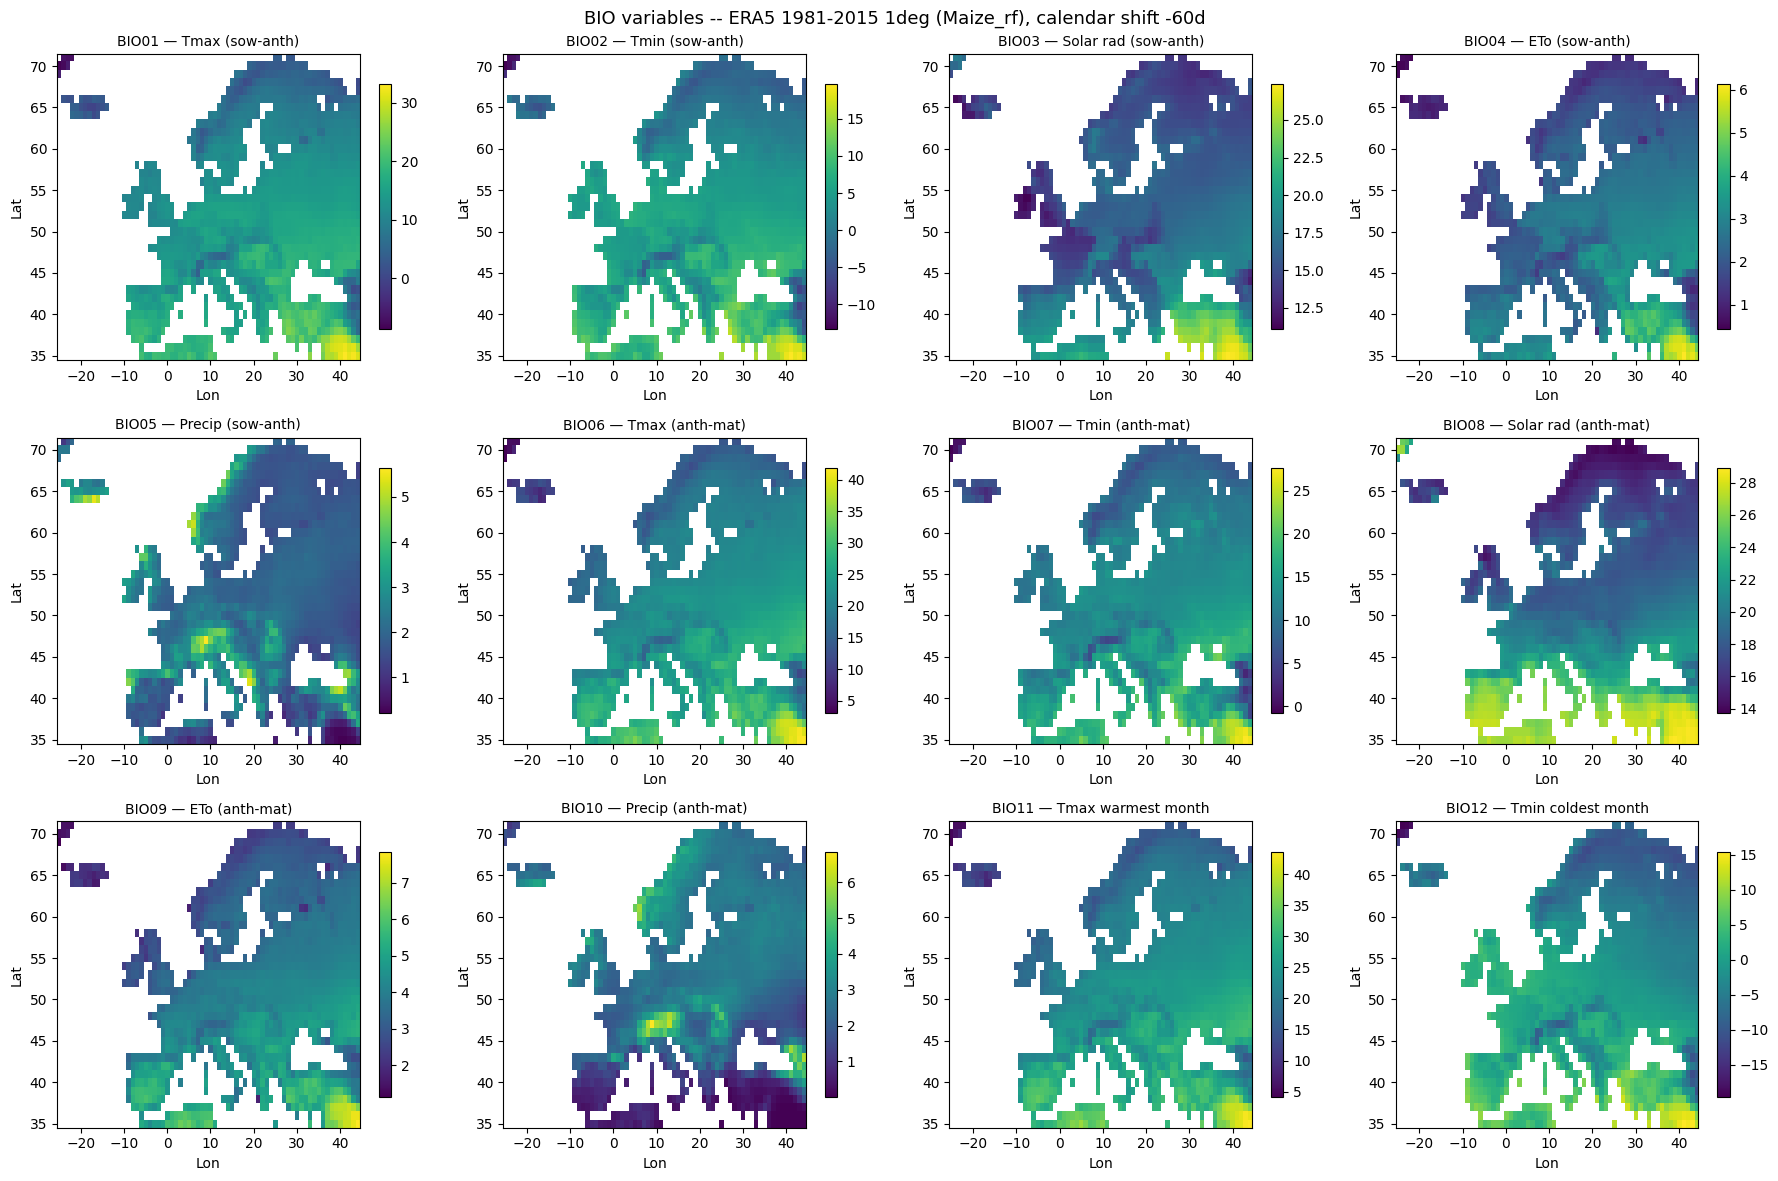

Done.


In [16]:
ext = [target_lons[0]-0.5, target_lons[-1]+0.5,
       target_lats_asc[0]-0.5, target_lats_asc[-1]+0.5]

fig, axes = plt.subplots(3, 4, figsize=(18, 12))
BIO_SHORT = {1: 'Tmax (sow-anth)', 2: 'Tmin (sow-anth)', 3: 'Solar rad (sow-anth)', 4: 'ETo (sow-anth)', 5: 'Precip (sow-anth)', 6: 'Tmax (anth-mat)', 7: 'Tmin (anth-mat)', 8: 'Solar rad (anth-mat)', 9: 'ETo (anth-mat)', 10: 'Precip (anth-mat)', 11: 'Tmax warmest month', 12: 'Tmin coldest month'}
for i, ax in enumerate(axes.flatten(), 1):
    arr = bio[i].copy(); arr[~land_mask] = np.nan
    im = ax.imshow(arr, origin='lower', aspect='auto', extent=ext)
    ax.set_title(f'BIO{i:02d} — {BIO_SHORT[i]}', fontsize=10); ax.set_xlabel('Lon'); ax.set_ylabel('Lat')
    plt.colorbar(im, ax=ax, shrink=0.8)
plt.suptitle(f'BIO variables -- ERA5 1981-2015 1deg ({season_label}), calendar shift {CALENDAR_SHIFT_DAYS:+d}d', fontsize=13)
plt.tight_layout()
_png_out = OUT_ERA5 / f'BIOmaps_{season_label}_{shift_tag}.png'
save_with_retry(lambda: plt.savefig(_png_out, dpi=100), _png_out)
plt.show()
print("Done.")